# Figure 5A — how often is a combination more than the sum of its parts?

For each pair of guide modules, counts the response genes the combination
significantly affects, split by whether the combination also departs from
additivity. Same-module pairs are drawn first, then cross-module pairs.

The bars do not sum to a constant: each one counts the genes that combination
affects, which ranges from 58 to 299.

## Setup

In [1]:
library(ggplot2)
library(data.table)   # before reshape2: both define melt()
library(reshape2)

# NOTE: Main.R is deliberately not sourced. It loads ICtest, whose Ops method
# conflicts with the S7 objects in ggplot2 4.x and silently breaks every "+"
# chain, producing a blank PDF. %ni% is inlined from Utilities.R.

`%ni%` <- Negate(`%in%`)

# Written by ../combinatorial_perturbations/01-05 and committed there, so this
# notebook runs from a clone without regenerating them. A re-run of those
# notebooks writes to their outputs/ and leaves these untouched.
RDS_DIR <- "../combinatorial_perturbations/RDSFiles"

FDR_CUTOFF <- 0.1

# Terms are keyed by the old module names; they are relabelled only for display.
MODULE_OF_K <- c("0" = "M2", "1" = "M3", "2" = "M6", "3" = "M5", "4" = "M1", "5" = "M4")
moduleLabel <- function(x) {
    for (k in names(MODULE_OF_K)) x <- gsub(paste0("K_?", k), MODULE_OF_K[[k]], x)
    x
}

# Terms arrive in three shapes across the files -- K_0, K_0WK_1, K0 -- and are
# normalised to K0 and K0:K1 so the tables can be joined on them.
normaliseTerm <- function(x) gsub("_", "", gsub("W", ":", x))


Attaching package: ‘reshape2’


The following objects are masked from ‘package:data.table’:

    dcast, melt




## Which genes each combination affects

All three regression tables are long: one row per response gene per term, with
the nuisance covariates mixed in among the perturbation terms. Each is reduced
to the perturbation terms and FDR corrected *within* each response gene, which
is how the published analysis called significance.

`keep = "interactions"` additionally drops the single-module main effects, so
only the `K_i:K_j` product terms survive.

In [2]:
readComboEffects <- function(file, keep = c("all", "interactions")) {
    keep <- match.arg(keep)

    d <- readRDS(file.path(RDS_DIR, file))
    d <- d[d$term %ni% c("(Intercept)", "n_genes", "mt_frac", paste0("leiden", 1:9)), ]

    d <- data.table(d)
    d[, FDR := p.adjust(p.value, method = "fdr", n = length(p.value)), by = respGene]
    d <- data.frame(d)

    if (keep == "interactions") d <- d[d$term %ni% paste0("K_", 0:5), ]

    d$term <- normaliseTerm(d$term)
    d[, c("respGene", "term", "FDR")]
}

Two sources, because a combination of two knockouts from one module and a
combination across two modules were fitted by different models.

Within one module the knockouts are interchangeable, so the fit carries a
single main effect per module; it is renamed `K0:K0` to sit in the same column
as the cross-module pairs. `K5` is dropped: module 5 is M4, and no
within-module interaction was ever fitted for it, so it has nothing to be
compared against.

In [3]:
sameModule <- readComboEffects("ComboEffects_doublesSameGroup.rds")
sameModule <- sameModule[sameModule$term %in% paste0("K", 0:4), ]
sameModule$term <- paste0(sameModule$term, ":", sameModule$term)

crossModule <- readComboEffects("ComboEffects_lm_residuals.rds", keep = "interactions")

effects <- rbind(sameModule, crossModule)
names(effects)[names(effects) == "FDR"] <- "effectFDR"

c(genes = length(unique(effects$respGene)), terms = length(unique(effects$term)))

genes terms 
 1041    20

## Which of those effects are non-additive

Again two sources. Across modules, the `K_i:K_j` coefficients of the model
fitted *with* interaction terms. Within one module, the resampled within-module
interaction, which `combinatorial_perturbations/05` already pooled over five
half-splits, FDR corrected and zeroed where it failed.

:::{note}
`interaction` is not one quantity. For the cross-module terms it is an FDR. For
the same-module terms it is the **effect-size estimate** that notebook 05 left
behind: 80% of that column is exactly 0, and it spans -0.42 to +0.72. Testing it
against `FDR_CUTOFF` below therefore passes 95% of those rows, including every
zero and every negative one, so the five same-module bars come out almost
entirely blue by construction.

**This is deliberate and is not to be changed.** The panel is published, so it
reproduces the published numbers. Testing `!= 0` for the same-module rows --
the test notebook 05 actually describes, a gene being significant in at least
one of the five splits -- would take M2:M2 from 242 to 82 and M1:M1 from 90 to
31, leave every cross-module bar untouched, and drop all five same-module bars
below M2:M6 and M2:M5 at 103. That is recorded here so the discrepancy is known,
not as a change to make.
:::

In [4]:
sameModuleInter <- readRDS(file.path(RDS_DIR, "ComboEffects_doublesResampleRes.rds"))
sameModuleInter <- melt(sameModuleInter, id.vars = "respGene",
                        variable.name = "term", value.name = "interaction")
sameModuleInter$term <- as.character(sameModuleInter$term)

crossModuleInter <- readComboEffects("ComboEffects_lm_residuals_withInteractions.rds",
                                     keep = "interactions")
names(crossModuleInter)[names(crossModuleInter) == "FDR"] <- "interaction"

interactions <- rbind(sameModuleInter, crossModuleInter)

summary(interactions$interaction)

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-0.41837  0.01383  0.50329  0.45851  0.82099  0.99990 

## Counting

Joined on gene and term, restricted to the genes each combination significantly
affects, and tallied by whether the interaction is significant too. The legend
name `sgnInteraction` is the published one and is kept so the panel is
unchanged.

In [5]:
myAll <- merge(effects, interactions, by = c("respGene", "term"))
myAll <- myAll[myAll$effectFDR < FDR_CUTOFF, ]
myAll$sgnInteraction <- myAll$interaction < FDR_CUTOFF   # see the note above

myAll <- as.data.frame(table(term = myAll$term, sgnInteraction = myAll$sgnInteraction))

head(myAll)

,term,sgnInteraction,Freq
,<fct>,<fct>,<int>
1,K0:K0,FALSE,10
2,K0:K1,FALSE,181
3,K0:K2,FALSE,196
4,K0:K3,FALSE,123
5,K0:K4,FALSE,220
6,K0:K5,FALSE,152


## Bar order

Same-module terms first, then the cross-module pairs. Within each block the
bars are ordered by the blue segment -- the number of genes whose interaction
is significant -- largest first.

The order is derived from the counts rather than hardcoded, so it follows
`sgnInteraction` if the test above changes.

In [6]:
allTerms   <- unique(as.character(myAll$term))
isSame     <- vapply(strsplit(allTerms, ":"), function(x) x[1] == x[2], logical(1))

blueCount  <- setNames(rep(0, length(allTerms)), allTerms)
blue       <- myAll[as.character(myAll$sgnInteraction) == "TRUE", ]
blueCount[as.character(blue$term)] <- blue$Freq

# Ties break alphabetically so the order is reproducible.
orderBlock <- function(terms) terms[order(-blueCount[terms], terms)]
TERM_ORDER <- c(orderBlock(allTerms[isSame]), orderBlock(allTerms[!isSame]))

myAll$term <- factor(moduleLabel(as.character(myAll$term)),
                     levels = moduleLabel(TERM_ORDER))

# The order actually drawn, for the record.
data.frame(term        = moduleLabel(TERM_ORDER),
           block       = ifelse(TERM_ORDER %in% allTerms[isSame], "same", "cross"),
           significant = blueCount[TERM_ORDER],
           row.names   = NULL)

term,block,significant
<chr>,<chr>,<dbl>
M2:M2,same,242
M3:M3,same,206
M6:M6,same,136
M5:M5,same,95
M1:M1,same,90
M2:M6,cross,103
M2:M5,cross,103
M3:M5,cross,84
M3:M6,cross,71


## Figure 5A

agg_record_701539037 
                   2

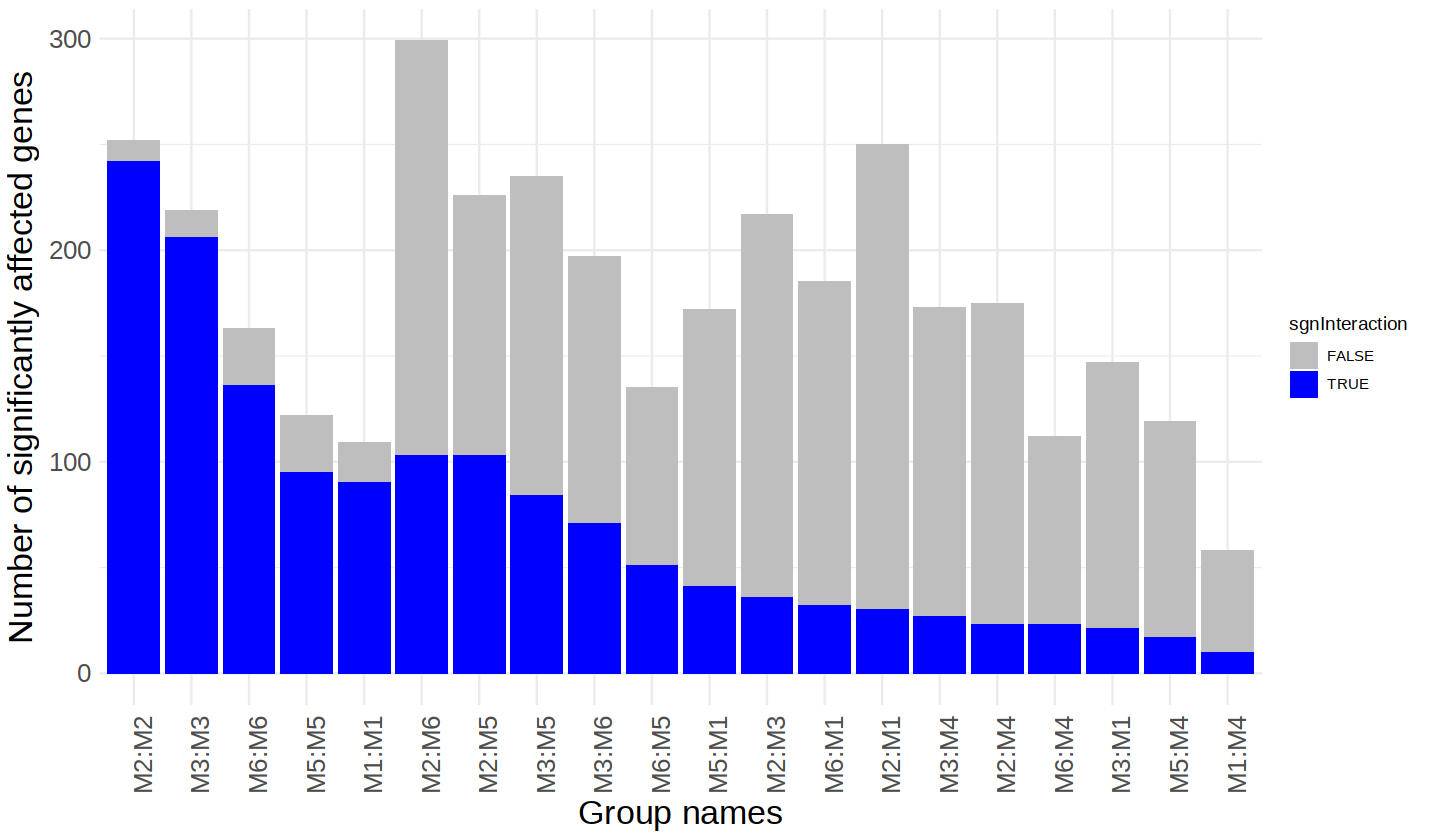

In [7]:
options(repr.plot.width = 12, repr.plot.height = 7)

p <- ggplot(myAll, aes(fill = sgnInteraction, y = Freq, x = term)) +
        geom_bar(position = "stack", stat = "identity") +
        scale_fill_manual(values = c("grey", "blue")) +
        theme_minimal() +
        theme(axis.text.y  = element_text(size = 15),
              axis.text.x  = element_text(size = 15, angle = 90),
              axis.title   = element_text(size = 20),
              strip.text   = element_text(size = 25)) +
        ylab("Number of significantly affected genes") +
        xlab("Group names")

pdf("figures/Figure_5A.pdf", width = 12, height = 6)
print(p)
dev.off()

p   # show it in the notebook as well as saving it